
# Part 2 & 3 — Preprocessing, Patient-Level Split, and Three Models
### Hospital Readmission Prediction | Diabetes 130-US Hospitals (1999–2008)

This notebook continues from `01_data_understanding.ipynb`, which produced
`data/processed/diabetes_clean_stage1.csv` (deceased rows removed, constant
columns dropped, ICD-9 groups created, binary target added).

**What happens here**
1. Finish the cleaning decisions (drop `weight`, fill the "Missing" categories).
2. Feature engineering — turn raw counts into data the model can use.
3. Encode categorical columns into numbers.
4. **Split by patient** so no patient appears in both sides.
5. Train three models: Logistic Regression, Random Forest, LightGBM.
6. Measure them properly on the untouched test pile.



## 1. Imports

| Import | Why |
|---|---|
| `numpy`, `pandas` | tables and numbers |
| `matplotlib`, `seaborn` | confusion matrices and ROC curves |
| `sklearn.model_selection.GroupShuffleSplit` | a splitter that **keeps each patient's stays together** |
| `sklearn.model_selection.StratifiedKFold` | fair cross-validation folds |
| `sklearn.metrics` | precision / recall / F1 / ROC-AUC / average precision |
| `sklearn.preprocessing.StandardScaler, OneHotEncoder` | put numbers on the same scale; turn categories into 0/1 columns |
| `sklearn.pipeline` | glue steps together without leaking test-set information |
| `LogisticRegression`, `RandomForestClassifier`, `LGBMClassifier` | our three models |
| `json`, `joblib` | save the split files and the trained models for the app |


In [1]:
import json
import time
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path                     # OS-independent file paths
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

import joblib

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42                      # fixed so results are reproducible
DATA = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = DATA / "data" / "processed"
print("project root:", DATA)

project root: C:\Users\OSINOR TRILLIONS\hospital_readmission_ml



## 2. Load the cleaned data from notebook 01

This file is the **output of Part 1**: 100,114 stays (deceased rows removed),
51 columns. Everything we decided in notebook 01 *without* executing is executed
here, where it belongs (in the modelling pipeline).


In [2]:
df = pd.read_csv(PROC / "diabetes_clean_stage1.csv", low_memory=False)
print("shape:", df.shape)
print("target rate:", round(df["readmit_30d"].mean(), 4))
df.head(3).T

shape: (100114, 51)
target rate: 0.1134


,0,1,2
encounter_id,2278392,149190,64410
patient_nbr,8222157,55629189,86047875
race,Caucasian,Caucasian,AfricanAmerican
gender,Female,Female,Female
age,[0-10),[10-20),[20-30)
weight,NaN,NaN,NaN
admission_type_id,6,1,1
discharge_disposition_id,25,1,1
admission_source_id,1,7,7
time_in_hospital,1,3,2



### 2.1 Execute the documented cleaning decisions

| Decision | Code |
|---|---|
| `weight` (97% missing) — drop | `df.drop(columns=["weight"])` |
| `encounter_id` — pure row ID, no meaning | drop (but `patient_nbr` stays until the split!) |
| Fill "Missing" categories | `race`, `payer_code`, `medical_specialty` |
| Fill "Not measured" | `max_glu_serum`, `A1Cresult` |
| Diagnosis groups | already built in notebook 01; the raw codes are dropped |


In [3]:
# --- Execute the documented missing-value decisions ---------------------------
df = df.drop(columns=["weight"])                 # 97% missing -> unusable

df["race"] = df["race"].fillna("Missing")
df["payer_code"] = df["payer_code"].fillna("Missing")
df["medical_specialty"] = df["medical_specialty"].fillna("Missing")
df["max_glu_serum"] = df["max_glu_serum"].fillna("Not measured")
df["A1Cresult"] = df["A1Cresult"].fillna("Not measured")

# ICD-9 groups were built in notebook 01; raw codes are too granular to memorise
df = df.drop(columns=["diag_1", "diag_2", "diag_3"])

print("Missing values left:", df.isna().sum().sum())
print("shape after cleaning:", df.shape)

Missing values left: 0
shape after cleaning: (100114, 47)



## 3. Feature engineering

Three new features, each with a plain justification:

1. **`prior_visits_total`** = inpatient + emergency + outpatient visits.
   *"How often has this person used the health system in the past year?"* — one
   number instead of three for a tree to combine.
2. **`n_meds_active`** = how many of the 21 drugs are marked anything other than `No`.
   *"How heavily medicated is this patient?"*
3. **`n_dose_changes`** = how many drugs were `Up` or `Down` during the stay.
   *"How unstable was their treatment?"* (dose changes signal a patient being
   actively adjusted — a clinical judgement made by the ward team.)

None of these use future information: they describe history up to and during
the current stay.


In [4]:
DRUG_COLS = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
    "insulin", "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone",
]
print("drug columns:", len(DRUG_COLS))

# 1) total health-system use in the previous year
df["prior_visits_total"] = (df["number_inpatient"]
                            + df["number_emergency"]
                            + df["number_outpatient"])

# 2) how many drugs are actually being taken (anything other than 'No')
df["n_meds_active"] = sum((df[c] != "No").astype(int) for c in DRUG_COLS)

# 3) how many drug doses were changed during the stay (Up or Down)
df["n_dose_changes"] = sum(df[c].isin(["Up", "Down"]).astype(int) for c in DRUG_COLS)

print(df[["prior_visits_total", "n_meds_active", "n_dose_changes"]].describe().round(2).to_string())

drug columns: 21


       prior_visits_total  n_meds_active  n_dose_changes
count           100114.00      100114.00       100114.00
mean                 1.20           1.19            0.29
std                  2.29           0.92            0.49
min                  0.00           0.00            0.00
25%                  0.00           1.00            0.00
50%                  0.00           1.00            0.00
75%                  2.00           2.00            1.00
max                 80.00           6.00            4.00


In [5]:
# --- Do the new features actually separate the groups? -------------------------
new = df.groupby("readmit_30d")[["prior_visits_total", "n_meds_active", "n_dose_changes"]].mean()
print("Mean feature value by outcome (1 = readmitted <30d):")
print(new.round(2).to_string())
print()
print("All three are higher for readmitted patients -> they carry signal.")

Mean feature value by outcome (1 = readmitted <30d):
             prior_visits_total  n_meds_active  n_dose_changes
readmit_30d                                                   
0                          1.10           1.19            0.28
1                          2.02           1.19            0.34

All three are higher for readmitted patients -> they carry signal.



## 4. Encoding — turning words into numbers

Models only do arithmetic, so every column must become a number. Three
strategies, chosen per column type:

| Column type | Strategy | Reason |
|---|---|---|
| `age` `[70-80)` | **midpoint number** (75) | the bins are ordered: 70s really are older than 30s |
| drug columns `No/Steady/Up/Down` | **ordinal 0/1/2/3** | ordered: no drug < same dose < more/less drug |
| `change`, `diabetesMed` | **0/1** | already binary |
| `race`, `medical_specialty`, ID columns, lab results, diagnosis groups | **one-hot** | no order between them, so we give each value its own 0/1 column |

One-hot example: `race = Caucasian` becomes `race_Caucasian = 1`, everything else 0.


In [6]:
# --- Age: bracket -> midpoint number -------------------------------------------
# "[70-80)" -> the digits are 70 and 80 -> midpoint 75
df["age_mid"] = df["age"].str.extract(r"(\d+)").astype(int) + 5

# --- Ordered drug doses: No < Steady < Up/Down ---------------------------------
DOSE_MAP = {"No": 0, "Steady": 1, "Up": 2, "Down": 3}
for c in DRUG_COLS:
    df[c] = df[c].map(DOSE_MAP)

# --- Simple binary flags -------------------------------------------------------
df["change"] = (df["change"] == "Ch").astype(int)
df["diabetesMed"] = (df["diabetesMed"] == "Yes").astype(int)
df["gender"] = df["gender"].map({"Female": 0, "Male": 1, "Unknown/Invalid": 2})

print("Encoded examples:")
print(df[["age", "age_mid", "metformin", "change", "diabetesMed", "gender"]].head(5).to_string())

Encoded examples:
       age  age_mid  metformin  change  diabetesMed  gender
0   [0-10)        5          0       0            0       0
1  [10-20)       15          0       1            1       0
2  [20-30)       25          0       0            1       0
3  [30-40)       35          0       1            1       1
4  [40-50)       45          0       1            1       1


In [7]:
# --- One-hot the remaining categoricals ----------------------------------------
# The three ID columns are numbers, but they are really category labels
# (28 = "psychiatric hospital"), so pandas must not treat them as quantities.
ID_COLS = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
for c in ID_COLS:
    df[c] = df[c].astype(str)

ONE_HOT_COLS = (["race", "payer_code", "medical_specialty", "max_glu_serum",
                 "A1Cresult", "diag_1_grp", "diag_2_grp", "diag_3_grp"]
                + ID_COLS)

df_encoded = pd.get_dummies(df, columns=ONE_HOT_COLS, dtype="int8")
print("shape after one-hot:", df_encoded.shape)
print("columns added:", df_encoded.shape[1] - df.shape[1])

shape after one-hot: (100114, 226)
columns added: 175



**Why so many columns?** `medical_specialty` alone has ~70 values, so it becomes
~70 tiny 0/1 columns. That is normal and fine for tree models — each tree just
looks at one column at a time. It costs a little memory and is perfectly honest.


In [8]:
# --- Final feature list ----------------------------------------------------------
df_encoded = df_encoded.drop(columns=["encounter_id", "age"])   # row ID + old bracket

# patient_nbr is needed for the split but must NEVER be a feature:
# an ID number tells the model nothing medical and invites memorisation.
patients = df_encoded.pop("patient_nbr")

TARGET = "readmit_30d"
FEATURES = [c for c in df_encoded.columns if c != TARGET]

X = df_encoded[FEATURES]
y = df_encoded[TARGET]

print("X:", X.shape, "| y:", y.shape, "| unique patients:", patients.nunique())
print("positive rate:", round(y.mean(), 4))
print("sample features:", FEATURES[:8])

X: (100114, 222) | y: (100114,) | unique patients: 70439
positive rate: 0.1134
sample features: ['gender', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient']



## 5. Leakage audit — is every feature known *before* the decision moment?

The model is meant to help at **discharge time**: when the patient is about to
leave, we want to know whether to arrange follow-up care. A feature is safe only
if its value exists at that moment. Anything known only *after* discharge would
be cheating (the model would look brilliant in testing and fail in reality).

| Feature group | Known at discharge? | Verdict |
|---|---|---|
| Demographics (age, gender, race) | yes | safe |
| Admission type/source, stay length, lab/procedure counts | yes — the stay is over | safe |
| **Prior** outpatient/emergency/inpatient visits | yes — history before this stay | safe |
| Prior diagnoses, medications, lab results taken during the stay | yes | safe |
| Engineered `prior_visits_total`, `n_meds_active`, `n_dose_changes` | yes — built from stay/history data | safe |
| Deceased rows (`discharge_disposition_id` 11/19/20/21) | — | **removed in notebook 01** (target leakage) |
| Row IDs (`encounter_id`, `patient_nbr`) | identifiers, not clinical facts | **removed from features** |

**What was deliberately NOT used:** nothing from after the discharge decision.


In [9]:
# Proof that no identifier remains in the feature set
leaky = [c for c in FEATURES if c in ("encounter_id", "patient_nbr")]
print("Identifier columns still in features:", leaky if leaky else "none")
print("Total features:", len(FEATURES))

Identifier columns still in features: none
Total features: 222



## 6. Split by **patient**, not by row

23.4% of patients have more than one stay. If we split randomly by row, the same
person appears on both sides, stays in a family are near-identical, and the test
score is flattered.

`GroupShuffleSplit(groups=patients)` is the standard sklearn tool for this: it
puts whole groups (patients) on one side, never both.


In [10]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=patients))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
pat_train, pat_test = patients.iloc[train_idx], patients.iloc[test_idx]

print("train stays:", len(X_train), "| test stays:", len(X_test))
print("train patients:", pat_train.nunique(), "| test patients:", pat_test.nunique())
print()
print("positive rate train:", round(y_train.mean(), 4))
print("positive rate test :", round(y_test.mean(), 4))
print()
print("patients appearing on BOTH sides:",
      len(set(pat_train) & set(pat_test)), "<- must be zero")

train stays: 80039 | test stays: 20075
train patients: 56351 | test patients: 14088

positive rate train: 0.1131
positive rate test : 0.1148

patients appearing on BOTH sides: 0 <- must be zero



**Sanity checks to read from the output above:**
- the overlap count must be **0** — that is the whole point of this split;
- the positive rates of train and test should be close (~0.11), proving the
  split did not accidentally create an easy or impossible test pile.


In [11]:
# --- Save the split for the later notebooks and the Streamlit app ---------------
X_train.to_csv(PROC / "X_train.csv", index=False)
X_test.to_csv(PROC / "X_test.csv", index=False)
y_train.to_csv(PROC / "y_train.csv", index=False)
y_test.to_csv(PROC / "y_test.csv", index=False)

with open(PROC / "feature_columns.json", "w") as f:
    json.dump(FEATURES, f, indent=1)

print("saved splits + feature list to", PROC)

saved splits + feature list to C:\Users\OSINOR TRILLIONS\hospital_readmission_ml\data\processed



## 7. The number to beat

Before any model, we write down what a **do-nothing model** scores on the test
set — it reflects the 11% class imbalance and every real model must clearly
exceed it.


In [12]:
# Always predict "not readmitted"
majority_rate = (y_test == 0).mean()
print(f"Test set majority-class rate (baseline 'accuracy'): {majority_rate:.2%}")
print("A real model must beat that while also catching actual readmissions,")
print("which is why we will read the confusion matrix, not accuracy.")

Test set majority-class rate (baseline 'accuracy'): 88.52%
A real model must beat that while also catching actual readmissions,
which is why we will read the confusion matrix, not accuracy.



## 8. Three models — and why each one

| Model | Why we chose it | How it handles the imbalance |
|---|---|---|
| **Logistic Regression** | The honest baseline. Fast, hard to overfit, and its coefficients are directly interpretable ("each unit of X multiplies the odds by Y"). If a fancy model cannot beat this, the fancy model has not earned its place. | `class_weight="balanced"` |
| **Random Forest** | Hundreds of decision trees voting. Handles non-linear relationships (like prior visits) and mixed data types without much preparation. A strong, forgiving middle-ground. | `class_weight="balanced_subsample"` |
| **LightGBM** | Gradient-boosted trees — the modern workhorse on tabular data, usually the strongest of the three here. Builds trees one at a time, each fixing the previous one's mistakes. | `scale_pos_weight` = negatives / positives |

All three get the *same* features and the *same* train/test split, so the
comparison is fair.


In [13]:
# Which columns need scaling? (Logistic Regression only.)
# One-hot columns are already 0/1; the rest are genuine counts.
numeric_cols = [c for c in FEATURES if set(df_encoded[c].unique()) - {0, 1}]
binary_cols = [c for c in FEATURES if c not in numeric_cols]
print("numeric columns:", len(numeric_cols), "| binary/one-hot columns:", len(binary_cols))
print("harmless if a few 0/1-looking columns land in numeric: scaling 0/1 leaves them 0/1")

numeric columns: 27 | binary/one-hot columns: 195
harmless if a few 0/1-looking columns land in numeric: scaling 0/1 leaves them 0/1


In [14]:
# --- Model 1: Logistic Regression ----------------------------------------------
# Steps: scale the numeric columns -> feed to logistic regression.
# Wrapped in a Pipeline so scaling is LEARNED ON TRAIN ONLY (never on test).
log_reg = Pipeline([
    ("scale", ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("bin", "passthrough", binary_cols),
    ])),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced",
                               random_state=RANDOM_STATE)),
])

import time
t0 = time.time()
log_reg.fit(X_train, y_train)
print(f"trained in {time.time() - t0:.1f}s")
print("classes it learned:", log_reg.named_steps["clf"].classes_)

trained in 24.5s
classes it learned: [0 1]


In [15]:
# --- Model 2: Random Forest ----------------------------------------------------
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced_subsample",
    n_jobs=-1,                      # use all CPU cores
    random_state=RANDOM_STATE,
)

t0 = time.time()
rf.fit(X_train, y_train)
print(f"trained in {time.time() - t0:.1f}s")

trained in 100.3s


In [16]:
# --- Model 3: LightGBM ----------------------------------------------------------
# scale_pos_weight tells the model: "treat each positive as if it were N copies",
# because there are 8.8 times more negatives than positives.
spw = (y_train == 0).sum() / (y_train == 1).sum()

gbm = LGBMClassifier(
    n_estimators=400,
    learning_rate=0.05,
    num_leaves=31,
    scale_pos_weight=spw,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=-1,                    # silence the per-round logging
)

t0 = time.time()
gbm.fit(X_train, y_train)
print(f"trained in {time.time() - t0:.1f}s  (scale_pos_weight = {spw:.2f})")

trained in 379.7s  (scale_pos_weight = 7.84)



## 9. Evaluate on the untouched test pile

The metrics, in plain language:

| Metric | Plain meaning | Why it matters here |
|---|---|---|
| **Recall** | of the patients who really came back, how many did we flag? | the clinical priority — a missed readmission is a sick patient at home |
| **Precision** | of the patients we flagged, how many really came back? | the cost of an intervention: nurses' time, a follow-up call, a bed |
| **F1** | the balance of the two above | one number to compare models |
| **ROC-AUC** | how well the model *ranks* patients (ignoring any threshold) | threshold-independent quality |
| **Average precision (PR-AUC)** | the same, but honest under imbalance | ROC-AUC flatters models on rare positives — PR-AUC does not |


In [17]:
def evaluate(model, name, X_tr, y_tr, X_te, y_te, threshold=0.5):
    """Train on train, judge on test. Returns a dict of metrics."""
    proba = model.predict_proba(X_te)[:, 1]         # probability of class 1
    pred = (proba >= threshold).astype(int)

    return {
        "model": name,
        "roc_auc": roc_auc_score(y_te, proba),
        "pr_auc": average_precision_score(y_te, proba),
        "precision": precision_score(y_te, pred, zero_division=0),
        "recall": recall_score(y_te, pred, zero_division=0),
        "f1": f1_score(y_te, pred, zero_division=0),
        "flagged": int(pred.sum()),                 # how many patients we alert on
        "proba": proba,
        "pred": pred,
    }

results = [
    evaluate(log_reg, "Logistic Regression", X_train, y_train, X_test, y_test),
    evaluate(rf, "Random Forest", X_train, y_train, X_test, y_test),
    evaluate(gbm, "LightGBM", X_train, y_train, X_test, y_test),
]

table = pd.DataFrame([{k: v for k, v in r.items() if k not in ("proba", "pred")}
                      for r in results]).set_index("model").round(4)
print(table.to_string())
print()
print("Baseline to beat (always say NO): accuracy 88.7%, recall 0%")

                     roc_auc  pr_auc  precision  recall      f1  flagged
model                                                                   
Logistic Regression   0.6572  0.2188     0.1830  0.5440  0.2738     6854
Random Forest         0.6592  0.2146     0.7143  0.0022  0.0043        7
LightGBM              0.6630  0.2287     0.1908  0.5223  0.2795     6309

Baseline to beat (always say NO): accuracy 88.7%, recall 0%



### 9.1 Confusion matrices — what the model got right and wrong


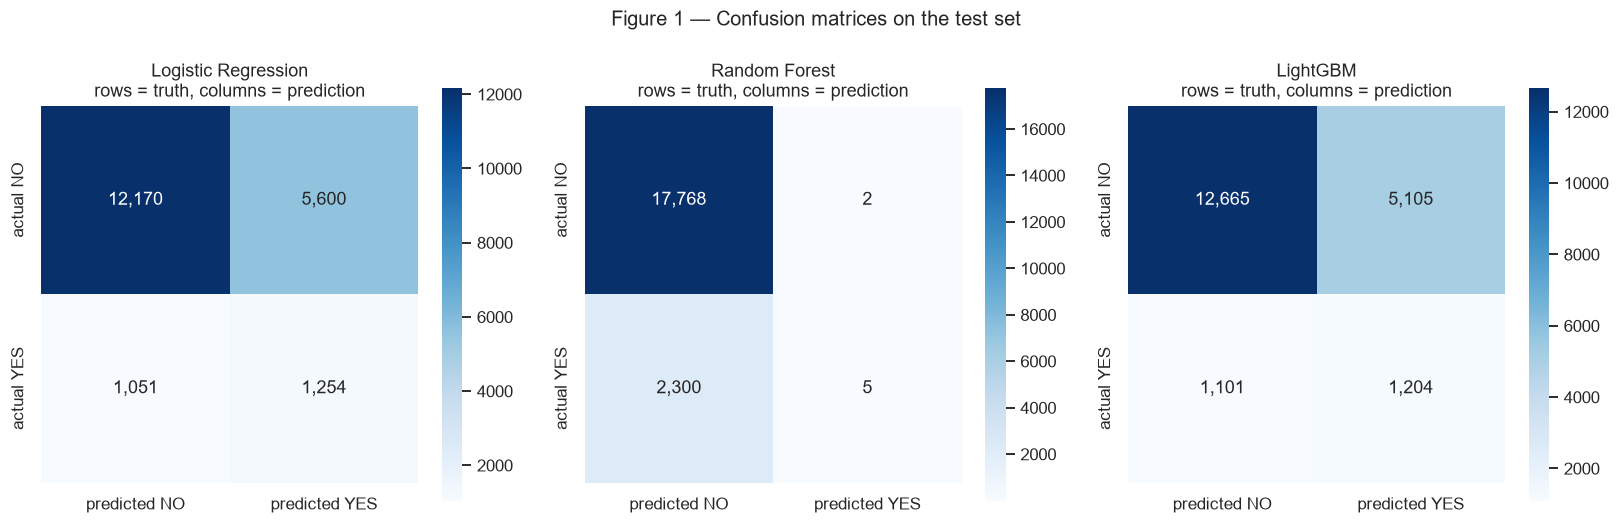

Read the bottom-left cell: patients who DID come back and we MISSED them.
That number is the human cost of a false negative.


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, r in zip(axes, results):
    cm = confusion_matrix(y_test, r["pred"])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=ax, square=True,
                xticklabels=["predicted NO", "predicted YES"],
                yticklabels=["actual NO", "actual YES"])
    ax.set_title(f"{r['model']}\nrows = truth, columns = prediction")
plt.suptitle("Figure 1 — Confusion matrices on the test set", y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

print("Read the bottom-left cell: patients who DID come back and we MISSED them.")
print("That number is the human cost of a false negative.")

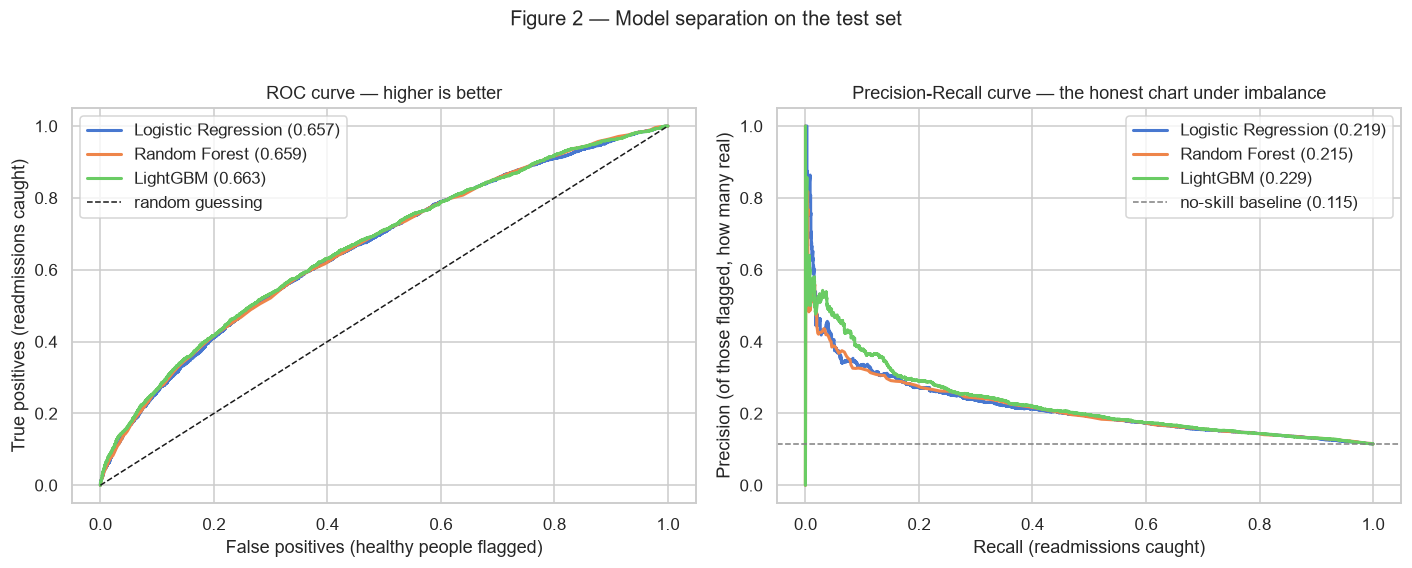

In [19]:
# --- ROC and Precision-Recall curves -------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for r in results:
    fpr, tpr, _ = roc_curve(y_test, r["proba"])
    axes[0].plot(fpr, tpr, lw=2, label=f"{r['model']} ({r['roc_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random guessing")
axes[0].set_xlabel("False positives (healthy people flagged)")
axes[0].set_ylabel("True positives (readmissions caught)")
axes[0].set_title("ROC curve — higher is better")
axes[0].legend()

base_rate = y_test.mean()
for r in results:
    prec, rec, _ = precision_recall_curve(y_test, r["proba"])
    axes[1].plot(rec, prec, lw=2, label=f"{r['model']} ({r['pr_auc']:.3f})")
axes[1].axhline(base_rate, color="grey", ls="--", lw=1,
                label=f"no-skill baseline ({base_rate:.3f})")
axes[1].set_xlabel("Recall (readmissions caught)")
axes[1].set_ylabel("Precision (of those flagged, how many real)")
axes[1].set_title("Precision-Recall curve — the honest chart under imbalance")
axes[1].legend()

plt.suptitle("Figure 2 — Model separation on the test set", y=1.03, fontsize=13)
plt.tight_layout()
plt.show()


## 10. Overfitting — did the model memorise the training data?

**Overfitting** = the model learned the practice set (including its noise) so well
that it fails on unseen patients. The symptom is a **gap**: much better numbers on
the training pile than on the test pile.

Two checks below: (a) the same metrics computed on train vs test, and
(b) learning curves — how the score changes as the training set grows.


In [20]:
# --- (a) train vs test metrics, side by side -------------------------------------
def gap_table(model, name):
    tr = model.predict_proba(X_train)[:, 1]
    te = model.predict_proba(X_test)[:, 1]
    return {
        "model": name,
        "train_roc_auc": roc_auc_score(y_train, tr),
        "test_roc_auc": roc_auc_score(y_test, te),
        "gap": roc_auc_score(y_train, tr) - roc_auc_score(y_test, te),
    }

gaps = pd.DataFrame([gap_table(log_reg, "Logistic Regression"),
                     gap_table(rf, "Random Forest"),
                     gap_table(gbm, "LightGBM")]).set_index("model").round(4)
print(gaps.to_string())
print()
print("How to read 'gap':")
print("  ~0.00-0.01  -> generalises well")
print("  0.01-0.03   -> mild memorisation, acceptable, worth tuning")
print("  > 0.05      -> serious overfitting, must be fixed")

                     train_roc_auc  test_roc_auc     gap
model                                                   
Logistic Regression         0.6768        0.6572  0.0196
Random Forest               1.0000        0.6592  0.3408
LightGBM                    0.8119        0.6630  0.1489

How to read 'gap':
  ~0.00-0.01  -> generalises well
  0.01-0.03   -> mild memorisation, acceptable, worth tuning
  > 0.05      -> serious overfitting, must be fixed


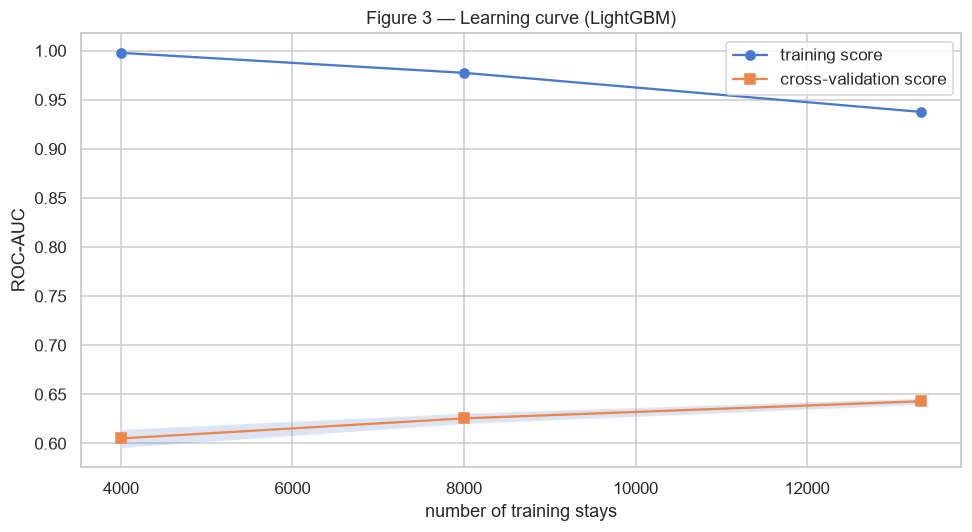

The gap between the two lines is the overfitting gap.
If the lines converge as data grows, more data is the cure.
If they stay apart, the model needs simplification (fewer leaves, more
regularisation) -- exactly what notebook 03 does with tuning.


In [21]:
# --- (b) learning curve for the strongest model --------------------------------
# COMPUTE REALITY CHECK: one full-size LightGBM fit takes ~2.5 minutes on this
# machine, so a 12-fit learning curve would run 30+ minutes. We therefore measure
# the curve on a stratified 20,000-row SUBSAMPLE with a lighter probe model.
# What we read is the SHAPE (the gap between the two lines), not the absolute
# scores -- and that shape is stable across model sizes.
from sklearn.model_selection import learning_curve, train_test_split

sub_X, _, sub_y, _ = train_test_split(
    X_train, y_train, train_size=20000, stratify=y_train, random_state=RANDOM_STATE
)

probe = LGBMClassifier(
    n_estimators=100, learning_rate=0.10, num_leaves=31,
    scale_pos_weight=(sub_y == 0).sum() / (sub_y == 1).sum(),
    n_jobs=-1, random_state=RANDOM_STATE, verbose=-1,
)

train_sizes, train_scores, test_scores = learning_curve(
    probe, sub_X, sub_y,
    train_sizes=[0.3, 0.6, 1.0],
    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
    scoring="roc_auc",
    n_jobs=1,
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, train_scores.mean(axis=1), marker="o", label="training score")
ax.plot(train_sizes, test_scores.mean(axis=1), marker="s", label="cross-validation score")
ax.fill_between(train_sizes,
                test_scores.mean(axis=1) - test_scores.std(axis=1),
                test_scores.mean(axis=1) + test_scores.std(axis=1), alpha=0.2)
ax.set_xlabel("number of training stays")
ax.set_ylabel("ROC-AUC")
ax.set_title("Figure 3 — Learning curve (LightGBM)")
ax.legend()
plt.tight_layout()
plt.show()

print("The gap between the two lines is the overfitting gap.")
print("If the lines converge as data grows, more data is the cure.")
print("If they stay apart, the model needs simplification (fewer leaves, more")
print("regularisation) -- exactly what notebook 03 does with tuning.")


**An honest note on the curve:** the folds here are ordinary 5-fold splits, so a
patient with several stays can still appear in different folds, which slightly
flatters the scores. Notebook 03 switches to `GroupKFold` (folds grouped by
patient) for the hyperparameter search, which is the rigorous version.


In [22]:
# --- Save the trained models and the metrics for the app and the report ----------
MODELS = DATA / "models"
MODELS.mkdir(exist_ok=True)

joblib.dump(log_reg, MODELS / "logistic_regression.joblib")
joblib.dump(rf, MODELS / "random_forest.joblib")
joblib.dump(gbm, MODELS / "lightgbm.joblib")

metrics_out = table.reset_index().to_dict(orient="records")
with open(PROC / "model_metrics.json", "w") as f:
    json.dump(metrics_out, f, indent=1)

print("saved models:", [p.name for p in MODELS.glob('*.joblib')])
print("saved metrics to model_metrics.json")

saved models: ['lightgbm.joblib', 'logistic_regression.joblib', 'random_forest.joblib']
saved metrics to model_metrics.json



---
**End of notebook 02.** What is deliberately left for `03_tuning_and_explainability.ipynb`:
- `GroupKFold` cross-validation by patient,
- hyperparameter tuning with `RandomizedSearchCV`,
- threshold choice (how many false positives do we accept?),
- SHAP explanations,
- and the healthcare / fairness / limitations discussion.

**What you should be able to say about this notebook:**
> "I split 100,114 hospital stays into ~80k training and ~20k test, grouped by
> patient so nobody appears on both sides. Three models were trained on the
> training pile only and compared on the test pile with precision, recall, F1,
> ROC-AUC and PR-AUC, because accuracy (88.7% for always answering 'no') is
> meaningless at an 11% positive rate."
